# TD 3 : Réduction de dimension (CORRECTION)

**BUT INFO3 Développeur IA, R5.C.08, IA5, Partie 1**
M. Sakkari, IUT de La Rochelle

> **Version enseignant :** codes complétés et réponses aux questions.

## Dans ce TD, on apprend à...
- **résumer** un tableau qui a beaucoup de colonnes, en gardant seulement l'essentiel. On le fait pour deux raisons : pour **dessiner** les données (on ne dessine qu'en 2D ou 3D), et pour **faciliter l'analyse** (calculs plus rapides, moins de colonnes qui se répètent). Le prix à payer : on perd un peu d'information ;
- **dessiner** sur un graphique en 2D des données qui ont des centaines de colonnes ;
- **résumer une courbe** qui évolue dans le temps.

On utilise cinq méthodes : PCA, t-SNE, UMAP, PAA et APCA. Chacune est expliquée avant d'être utilisée.

## Les données
- **2 000 avis Amazon** de produits alimentaires : chaque avis a une note de 1 à 5, un texte et un nombre de votes « avis utile ».
- **La note moyenne par mois** d'un produit.


## Petit lexique avant de commencer

| Mot | Ce que ça veut dire | Exemple |
|---|---|---|
| **Tableau** (*DataFrame*) | des données rangées en lignes et en colonnes, comme dans Excel | une ligne = un avis, une colonne = une information |
| **Colonne** (ou **variable**) | une information mesurée | la note, la longueur de l'avis |
| **Dimension** | le nombre de colonnes | un tableau à 500 colonnes a 500 dimensions |
| **Moyenne** | on additionne les valeurs, puis on divise par leur nombre | moyenne de 10, 12 et 20 : 14 |
| **Écart-type** | l'écart moyen entre les valeurs et la moyenne. Plus il est grand, plus les valeurs sont étalées | notes 10, 12, 14, 16, 18 : écart-type ≈ 3,2 (calcul détaillé sous le tableau) |
| **Variance** | une autre façon de mesurer l'étalement des valeurs | 10, 10, 10 : variance nulle (tout est pareil). 1, 10, 19 : variance grande |
| **Projeter** | dessiner des points sur un plan plus simple, comme l'ombre d'un objet sur un mur | un objet en 3D devient une ombre en 2D |
| **Amas** | un groupe de points collés les uns aux autres sur un graphique | des avis qui se ressemblent |

### L'écart-type : la formule, puis le calcul

**Formule.** Pour *n* valeurs $x_1, x_2, \dots, x_n$ de moyenne $m$ :

$$\text{écart-type} = \sqrt{\frac{(x_1 - m)^2 + (x_2 - m)^2 + \dots + (x_n - m)^2}{n - 1}}$$

**Calcul** avec les 5 notes 10, 12, 14, 16 et 18 (donc $n = 5$) :

1. **La moyenne :** $m = \dfrac{10 + 12 + 14 + 16 + 18}{5} = 14$
2. **L'écart de chaque note à la moyenne :** $10 - 14 = -4$ ; $12 - 14 = -2$ ; $14 - 14 = 0$ ; $16 - 14 = 2$ ; $18 - 14 = 4$
3. **Chaque écart au carré :** $16$ ; $4$ ; $0$ ; $4$ ; $16$
4. **L'écart-type :** $\sqrt{\dfrac{16 + 4 + 0 + 4 + 16}{5 - 1}} = \sqrt{\dfrac{40}{4}} = \sqrt{10} \approx 3{,}2$

**Pourquoi ces choix ?**
- **Le carré** : sans lui, les écarts négatifs et positifs s'annulent (-4 - 2 + 0 + 2 + 4 = 0).
- **La racine carrée** : elle ramène le résultat à la même unité que les notes (des points, pas des points au carré).
- **Diviser par n - 1** (ici 4, et 99 si on avait 100 notes) : c'est une convention, qui donne une meilleure estimation quand on travaille sur un échantillon.

**Lecture :** une note est en général à environ 3 points de la moyenne.

In [1]:
# Objectif : charger 2 000 avis Amazon tirés au hasard, pour travailler sur un jeu de données plus léger.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dossier contenant les fichiers de données
DATA = "../data"

# sample(n=2000) tire 2 000 avis au hasard
# random_state=42 fixe le tirage : tout le monde obtient les mêmes avis
# reset_index(drop=True) renumérote les lignes de 0 à 1999
df = pd.read_csv(f"{DATA}/amazon_reviews_sample.csv").sample(n=2000, random_state=42).reset_index(drop=True)
print("Dimensions :", df.shape)   # (nombre de lignes, nombre de colonnes)

Dimensions : (2000, 8)


# 1. Pourquoi réduire la dimension ?

### Concept

Un ordinateur ne comprend pas un texte : il lui faut des nombres. Avec le **TF-IDF** (*Term Frequency - Inverse Document Frequency*), on transforme chaque avis en une ligne de nombres :
- on choisit une liste de mots (ici 500) : une colonne par mot ;
- dans chaque case, on met un nombre qui indique **l'importance du mot dans l'avis**.

**Exemple** avec 3 avis et une liste de 4 mots (chien, chat, content, croquettes). Pour simplifier, on compte ici le nombre de fois où le mot apparaît :

| Avis | chien | chat | content | croquettes |
|---|---:|---:|---:|---:|
| A : « chien content » | 1 | 0 | 1 | 0 |
| B : « chien chat » | 1 | 1 | 0 | 0 |
| C : « chat content content croquettes » | 0 | 1 | 2 | 1 |

- Le tableau a **3 lignes** (3 avis) et **4 colonnes** (4 mots). Chaque **mot** est une **colonne**, chaque **avis** est une **ligne**.
- L'avis A contient « chien » et « content » mais ni « chat » ni « croquettes » : sa ligne est (1, 0, 1, 0).
- L'avis C contient « content » deux fois : il a un 2 dans cette colonne.

Avec une liste de 500 mots, on obtient 500 colonnes : chaque avis devient une ligne de 500 nombres. Le TF-IDF suit la même idée, mais il met dans la case l'**importance** du mot au lieu d'un simple comptage.

**Un avis garde tout son texte.** C'est le tableau qui ne retient que les mots de la liste. Les autres mots de l'avis sont ignorés : ils n'ont pas de colonne. Si un avis n'utilise aucun mot de la liste, sa ligne est remplie de 0.

**Comment la liste de 500 mots est-elle choisie ?**
1. On met tous les avis ensemble et on compte combien de fois chaque mot apparaît (en enlevant d'abord les mots très courants comme « the », « and », « is »).
2. On garde les 500 mots qui apparaissent le plus. C'est le réglage `max_features=500` de la démo.

**Pourquoi 500 ?** Il n'y a pas de règle : c'est un compromis. Voici ce qu'on obtient sur nos 2 000 avis quand on change seulement `max_features`. Au total, ces avis contiennent 9 505 mots différents.

| `max_features` | Mots de la liste présents dans un avis (en moyenne) | Cases à 0 | Avis dont la ligne est vide | Taille du tableau |
|---:|---:|---:|---:|---:|
| 20 | 3,5 | 82,5 % | 120 avis (6 %) | moins de 1 Mo |
| 100 | 8,5 | 91,5 % | 7 avis (0,4 %) | 2 Mo |
| **500** | **17,5** | **96,5 %** | **0** | **8 Mo** |
| 5 000 | 29,5 | 99,4 % | 0 | 80 Mo |

- **Trop peu de mots (20) :** un avis n'a que 3,5 mots de la liste en moyenne, et 6 % des avis n'en ont aucun. On décrit mal les avis.
- **Beaucoup de mots (5 000) :** presque tout est à 0 (99,4 %), le tableau est 10 fois plus gros qu'avec 500 mots (80 Mo contre 8 Mo) et la PCA du TD prend environ 4 fois plus de temps.
- **500 mots :** tous les avis ont au moins un mot de la liste et le tableau reste petit. C'est un bon compromis pour ce TD.

On peut essayer d'autres valeurs en changeant `max_features` dans la démo.

Un mot qui revient souvent dans l'avis mais rarement dans les autres avis (par exemple « chien ») reçoit un nombre élevé. Un mot présent partout (comme « the ») reçoit un nombre proche de 0. Si l'avis ne contient pas le mot, la case vaut 0.

Résultat : chaque avis devient une ligne de 500 nombres, c'est-à-dire un point dans un espace à **500 dimensions**. Cela pose trois problèmes :
- on ne sait pas le dessiner (on ne dessine qu'en 2 ou 3 dimensions) ;
- les calculs sont plus lents ;
- beaucoup de colonnes sont inutiles ou se répètent. C'est ce qu'on appelle la « malédiction de la dimensionnalité ».

**Réduire la dimension**, c'est représenter les mêmes données avec moins de colonnes, en perdant le moins d'information possible.

### Démo : du texte aux nombres

In [2]:
# Objectif : transformer chaque avis (du texte) en 500 nombres, pour que l'ordinateur puisse le traiter.
from sklearn.feature_extraction.text import TfidfVectorizer

# max_features=500 : on garde les 500 mots les plus fréquents
# stop_words="english" : on ignore les mots très courants qui n'apportent rien (the, and, is...)
tfidf = TfidfVectorizer(max_features=500, stop_words="english")

# fit_transform : on apprend la liste des mots, puis chaque avis devient une ligne de 500 nombres
# toarray() met le résultat sous forme de tableau de nombres
X = tfidf.fit_transform(df["Text"]).toarray()
print("Dimension :", X.shape)   # (nombre d'avis, nombre de mots)

# Exemple concret : le premier avis, et ses nombres
print("\nPremier avis :", df["Text"][0][:200], "...")

mots = tfidf.get_feature_names_out()   # la liste des 500 mots (une colonne par mot)
valeurs = X[0]                         # les 500 nombres du premier avis

# On affiche les 5 mots les plus importants de cet avis
# (np.argsort donne les positions triées de la plus petite à la plus grande valeur ; [::-1] inverse l'ordre)
print("\nLes 5 mots les plus importants de cet avis :")
for i in np.argsort(valeurs)[::-1][:5]:
    print(f"  {mots[i]:<12} {valeurs[i]:.2f}")

# Tous les autres mots ont la valeur 0 : l'avis ne les contient pas
print("\nMots présents dans cet avis :", (valeurs > 0).sum(), "sur", len(valeurs))

Dimension : (2000, 500)

Premier avis : This chicken base is very smooth and melts right into whatever dish you add it to. The flavor and texture is comparable to McCormick's chicken base except this has a bit more of an onion flavor to it. ...

Les 5 mots les plus importants de cet avis :
  chicken      0.47
  salt         0.46
  flavor       0.28
  dish         0.28
  salty        0.25

Mots présents dans cet avis : 13 sur 500


### À vous : le tableau est-il bien rempli ?

On veut savoir si le tableau `X` contient surtout des valeurs utiles, ou surtout des zéros.

**À faire :** calculez la proportion de cases de `X` qui valent `0`.

**Questions :**
1. Quelle proportion trouvez-vous ?
2. Qu'est-ce que cela veut dire pour un avis ?

In [3]:
# Objectif : savoir si le tableau X contient surtout des valeurs utiles ou surtout des zéros.

# Étape 1 : (X == 0) donne True quand la case vaut 0
# Étape 2 : mean() donne la proportion de True
proportion_zero = round((X == 0).mean(), 3)
print("Proportion de zéros :", proportion_zero)

Proportion de zéros : 0.965


### Réponse

**Question 1 : quelle proportion de zéros ?**
Environ **96,5 %** des cases valent 0.

**Question 2 : qu'est-ce que cela veut dire pour un avis ?**
Un avis n'utilise qu'une petite partie des 500 mots. Pour tous les autres mots, la valeur est 0. On peut donc résumer chaque avis avec beaucoup moins de colonnes.

# 2. PCA (*Principal Component Analysis*)

### Concept

Imaginons un tableau avec seulement deux colonnes : la taille et le poids de personnes. Les deux évoluent ensemble (en général, plus on est grand, plus on est lourd). On pourrait **résumer** ces deux colonnes par une seule, par exemple « le gabarit ». On perd très peu d'information, et on a une colonne au lieu de deux.

C'est ce que fait la **PCA** (*Principal Component Analysis*, « analyse en composantes principales »), mais avec beaucoup de colonnes :
- elle crée de **nouvelles colonnes**, appelées **composantes**, qui sont des mélanges des colonnes d'origine : on multiplie chaque colonne d'origine par un nombre, appelé **poids**, puis on additionne ;
- elle les range de la plus utile à la moins utile : la composante 1 garde le plus d'information, puis la 2, etc. ;
- on garde seulement les premières composantes.

**Comment mesure-t-elle « l'information » ?** Avec la **variance**. Plus les valeurs d'une colonne sont étalées, plus elle apporte de différences entre les lignes, donc d'information. Chaque composante a un **pourcentage de variance expliquée** : la part de l'information de départ qu'elle garde. Par exemple, 40 % veut dire qu'elle garde 40 % de l'information.

**Exemple :** on résume la taille et le poids de personnes par une seule colonne, le « gabarit ». Si cette composante a 95 % de variance expliquée :
- on **garde 95 %** de l'information de départ ;
- on **perd 5 %** de l'information de départ.

Ce qu'on perd, c'est par exemple le fait qu'une personne soit grande mais très mince : la colonne « gabarit » ne le montre pas.

**Attention aux échelles.** Les colonnes n'ont pas toutes les mêmes unités. Par exemple, la longueur d'un avis peut valoir 800 (caractères), alors qu'une note vaut au maximum 5.

La PCA cherche l'information là où les valeurs varient le plus. Elle croit donc que la longueur est bien plus importante que la note, simplement parce que ses nombres sont plus grands.

Pour éviter cela, on **standardise** avant : on remet toutes les colonnes sur la même échelle. Ainsi, aucune colonne ne l'emporte juste parce que ses nombres sont plus grands.

La PCA est dite **linéaire** : elle utilise des mélanges simples (des additions) des colonnes. Elle est rapide et facile à interpréter.

### Démo : PCA sur le texte

Variance expliquée : [0.025 0.018]
Total : 0.043


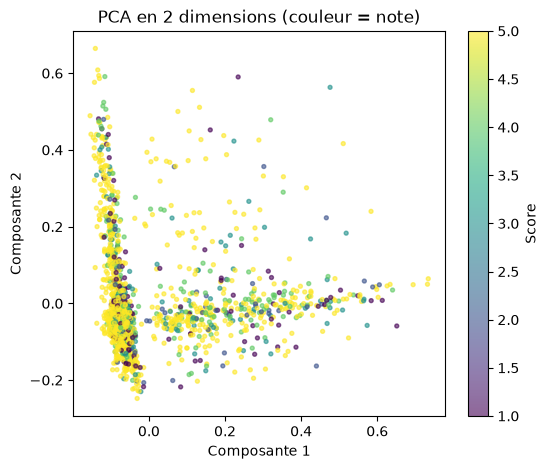

In [4]:
# Objectif : dessiner les 2 000 avis sur un graphique en 2 dimensions avec la PCA,
# et voir quelle part de l'information on garde.
from sklearn.decomposition import PCA

# n_components=2 : on demande 2 composantes, pour pouvoir dessiner en 2D
pca = PCA(n_components=2, random_state=42)

# fit_transform : la PCA calcule les composantes, puis projette chaque avis dessus
X_pca = pca.fit_transform(X)

# Part de variance (d'information) gardée par chaque composante
print("Variance expliquée :", pca.explained_variance_ratio_.round(3))
print("Total :", round(pca.explained_variance_ratio_.sum(), 3))

# Un point = un avis. La couleur du point = la note de l'avis (c=df["Score"])
fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=df["Score"], cmap="viridis", s=8, alpha=0.6)
plt.colorbar(sc, label="Score")
ax.set_xlabel("Composante 1")
ax.set_ylabel("Composante 2")
ax.set_title("PCA en 2 dimensions (couleur = note)")
plt.show()

### Démo : que représentent les deux composantes ?

Chaque composante est un **mélange des 500 colonnes de mots**, comme une recette de cuisine :

> composante = poids₁ × (mot 1) + poids₂ × (mot 2) + ... + poids₅₀₀ × (mot 500)

**Le poids** est le nombre qui dit quelle quantité de chaque mot on met dans la recette.
- Un poids **grand et positif** : le mot compte beaucoup, et il fait **monter** la valeur de la composante (plus l'avis contient ce mot, plus la valeur monte).
- Un poids **grand et négatif** : le mot compte beaucoup, mais il fait **baisser** la valeur de la composante (plus l'avis contient ce mot, plus la valeur baisse).
- Un poids **proche de 0** : le mot ne compte presque pas.

**Exemple :** pour résumer la taille et le poids en une seule colonne « gabarit », on peut utiliser la recette `gabarit = 0,7 × taille + 0,7 × poids`. Les deux poids valent 0,7 : les deux colonnes comptent autant.

**Qui choisit les poids ?** Ce n'est pas nous : c'est la PCA qui les calcule. Elle cherche les poids qui rendent la nouvelle colonne la plus étalée possible, donc celle qui distingue le mieux les avis. Pour cela, elle regarde quels mots varient beaucoup d'un avis à l'autre, et quels mots apparaissent ensemble. Par exemple, `coffee`, `tea` et `cup` apparaissent dans les mêmes avis : ils reçoivent de gros poids dans une même composante.

**Attention : ne confondez pas deux nombres.**

| | Ce qu'il mesure | Qui le calcule |
|---|---|---|
| **La valeur du TF-IDF** (dans le tableau) | l'importance du mot **dans un avis** | le TF-IDF, pour chaque avis |
| **Le poids** (dans une composante) | l'importance du mot **dans la composante** | la PCA, une seule fois pour tous les avis |

Pour comprendre ce que représente une composante, on regarde **les mots qui ont les poids les plus forts**.

In [5]:
# Objectif : voir quels mots comptent le plus dans chacune des deux composantes.

# La liste des 500 mots (une colonne par mot)
mots = tfidf.get_feature_names_out()

# pca.components_ contient les poids : une ligne par composante, 500 poids par ligne
for k in range(2):
    poids = pca.components_[k]        # les 500 poids de la composante k + 1
    ordre = np.argsort(poids)         # positions des mots, du poids le plus négatif au plus positif
    print(f"Composante {k + 1}")
    print("  poids positifs les plus forts :", [(mots[i], round(float(poids[i]), 2)) for i in ordre[::-1][:6]])
    print("  poids négatifs les plus forts :", [(mots[i], round(float(poids[i]), 2)) for i in ordre[:6]])
    print()

Composante 1
  poids positifs les plus forts : [('br', 0.97), ('food', 0.05), ('water', 0.04), ('natural', 0.03), ('cat', 0.03), ('little', 0.03)]
  poids négatifs les plus forts : [('coffee', -0.08), ('great', -0.07), ('love', -0.04), ('tea', -0.03), ('delicious', -0.03), ('order', -0.02)]

Composante 2
  poids positifs les plus forts : [('coffee', 0.76), ('tea', 0.25), ('cup', 0.22), ('br', 0.11), ('strong', 0.11), ('cups', 0.1)]
  poids négatifs les plus forts : [('food', -0.19), ('dog', -0.14), ('eat', -0.1), ('treats', -0.08), ('dogs', -0.08), ('loves', -0.07)]



**Lecture du résultat**

**Composante 1 : un défaut des données, pas un sujet.**
- Un seul mot domine : `br` (poids 0,97). Tous les autres ont un poids inférieur à 0,1.
- `<br />` est une balise HTML qui veut dire « aller à la ligne ». Elle est écrite telle quelle dans le texte des avis, par exemple : `...Donut Shop Original".<br /><br />Here is list of my favorites...`
- Le TF-IDF garde les lettres `br` de la balise et les compte comme un mot. Un avis écrit en plusieurs paragraphes contient donc beaucoup de « br ».
- La composante 1 mesure donc surtout « l'avis contient beaucoup de balises `<br />` (de retours à la ligne) ». Elle augmente avec la longueur de l'avis.
- Il faudrait enlever ces balises avant le TF-IDF.

**Composante 2 : les boissons contre la nourriture pour animaux.**
- Poids positifs forts : `coffee` (0,76), `tea`, `cup`. Poids négatifs : `food`, `dog`, `eat`, `treats`.
- Un avis haut sur cet axe parle de café ou de thé. Un avis bas parle de nourriture pour chiens ou chats.
- C'est un axe de **sujet** : de quoi parle l'avis.

**Sur le graphique de la PCA (plus haut) :**
- plus un avis contient de balises `<br />` (de retours à la ligne), plus son point est **à droite** ;
- plus un avis parle de café ou de thé, plus son point est **en haut**, et plus il parle de nourriture pour animaux, plus il est **en bas** ;
- la note ne ressort pas : c'est pour cela que les couleurs sont mélangées.

> **À retenir :** une composante n'est pas toujours un « sujet ». Regarder ses poids permet de comprendre ce qu'elle représente, et parfois de découvrir un défaut dans les données.

**Lecture :** les deux composantes gardent seulement environ 4 % de la variance. Autrement dit, le graphique ne montre que 4 % de l'information. Combien de composantes faudrait-il pour garder l'essentiel ?

### À vous : combien de composantes faut-il garder ?

On veut savoir combien de composantes il faut pour garder l'essentiel de l'information. La **variance cumulée** est la somme des variances expliquées : elle indique la part d'information gardée avec les premières composantes.

Exemple : si les composantes gardent 40 %, 20 % et 10 %, la variance cumulée est 40 %, puis 60 %, puis 70 %.

**À faire :** faites une PCA sur `X` en gardant toutes les composantes, calculez la variance cumulée, puis trouvez à partir de combien de composantes on dépasse 50 %, puis 80 %.

**Questions :**
1. Combien de composantes faut-il pour garder 50 % de la variance ? Et 80 % ?
2. Les 2 axes du graphique précédent suffisent-ils pour représenter les avis ?

50 % de variance : 104 composantes
80 % de variance : 252 composantes


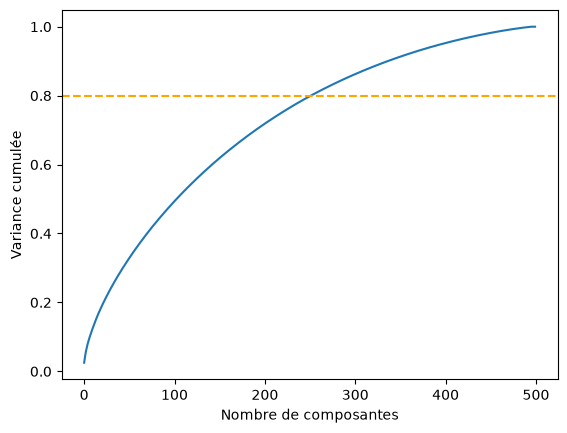

In [6]:
# Objectif : savoir combien de composantes il faut garder pour conserver l'essentiel de l'information.

# Étape 1 : PCA sur X en gardant toutes les composantes
pca_complete = PCA(random_state=42).fit(X)

# Étape 2 : variance cumulée (somme des variances expliquées)
variance_cumulee = np.cumsum(pca_complete.explained_variance_ratio_)

# Étape 3 : nombre de composantes pour dépasser 50 % puis 80 %
n_50 = int(np.argmax(variance_cumulee >= 0.5)) + 1
n_80 = int(np.argmax(variance_cumulee >= 0.8)) + 1
print("50 % de variance :", n_50, "composantes")
print("80 % de variance :", n_80, "composantes")

# Pour visualiser : courbe de la variance cumulée (la ligne orange marque 80 %)
plt.plot(variance_cumulee)
plt.axhline(0.8, color="orange", linestyle="--")
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance cumulée")
plt.show()

### Réponse

**Question 1 : combien de composantes pour garder 50 % ? Et 80 % ?**
- 50 % de la variance : **104** composantes
- 80 % de la variance : **252** composantes

**Question 2 : les 2 axes du graphique suffisent-ils ?**
Non. Deux axes gardent seulement environ 4 % de l'information. Le graphique en 2D est un résumé très pauvre. Pour du texte, la PCA compresse mal, car l'information est répartie sur beaucoup de mots différents.

> **À retenir :** on choisit le nombre de composantes avec la courbe de variance cumulée, pas au hasard.

### À vous : l'effet de l'échelle

On veut voir si la PCA donne le même résultat quand les colonnes n'ont pas la même échelle. On prend trois colonnes : la note (`Score`, de 1 à 5), la longueur du texte (`TextLength`, souvent plus de 500) et la part de votes « avis utile » (`HelpRatio`, entre 0 et 1).

In [7]:
# Objectif : construire 3 colonnes numériques pour chaque avis :
# la note, la longueur du texte et la part de votes "avis utile".

# Longueur de chaque avis, en nombre de caractères
df["TextLength"] = df["Text"].str.len()

# La colonne Helpfulness contient du texte comme "3/4" : 3 personnes sur 4 ont trouvé l'avis utile.
# Cette fonction transforme "3/4" en nombre : 3 / 4 = 0.75
def parse_help_ratio(h):
    try:
        num, den = h.split("/")          # on sépare "3/4" en "3" et "4"
        num, den = int(num), int(den)    # on transforme ces textes en nombres
        return num / den if den > 0 else 0.0   # si personne n'a voté (den = 0), on met 0
    except Exception:
        return 0.0

# map applique la fonction à chaque ligne de la colonne
df["HelpRatio"] = df["Helpfulness"].map(parse_help_ratio)

# Les trois colonnes numériques
numeriques = df[["Score", "TextLength", "HelpRatio"]]

# describe() résume chaque colonne : moyenne (mean), minimum (min), maximum (max)...
numeriques.describe().round(2)

,Score,TextLength,HelpRatio
count,2000.00,2000.00,2000.00
mean,4.15,455.93,0.41
std,1.32,481.55,0.46
min,1.00,70.00,0.00
25%,4.00,184.75,0.00
50%,5.00,306.00,0.00
75%,5.00,527.50,1.00
max,5.00,5469.00,1.50


**Lecture du tableau.** `count` est le nombre d'avis, `mean` la moyenne, `std` l'écart-type, `min` et `max` les valeurs extrêmes. Les lignes `25%`, `50%` et `75%` donnent les valeurs sous lesquelles se trouvent 25 %, 50 % et 75 % des avis (`50%` est la médiane).
- `Score` : la moyenne est de 4,15, entre 1 et 5.
- `TextLength` : la moyenne est de 456 caractères, mais le plus long avis en compte 5 469.
- `HelpRatio` : plus de la moitié des avis (54 %) valent 0 (personne n'a voté « utile »), et le maximum est 1,5. C'est bizarre : une part ne devrait pas dépasser 1. C'est une anomalie dans les données, qu'on laisse telle quelle ici.

On voit surtout que la colonne `TextLength` a des valeurs beaucoup plus grandes que les deux autres.

**À faire :** faites une PCA à 2 composantes sur `numeriques`, d'abord **sans** standardiser, puis **avec** standardisation (`StandardScaler`). Affichez la variance expliquée dans chaque cas.

**Questions :**
1. Que valent les variances expliquées dans les deux cas ?
2. Pourquoi les résultats sont-ils si différents ?

In [8]:
# Objectif : comparer la PCA sans standardisation et avec standardisation, pour voir ce que change l'échelle.
from sklearn.preprocessing import StandardScaler

# Partie 1 : PCA sans standardiser
pca_brut = PCA(n_components=2).fit(numeriques)
print("Sans standardisation :", pca_brut.explained_variance_ratio_.round(4))

# Partie 2 : PCA avec standardisation
# Étape 1 : standardiser les variables
numeriques_std = StandardScaler().fit_transform(numeriques)
# Étape 2 : refaire la PCA sur les données standardisées
pca_std = PCA(n_components=2).fit(numeriques_std)
print("Avec standardisation :", pca_std.explained_variance_ratio_.round(4))

Sans standardisation : [1. 0.]
Avec standardisation : [0.3803 0.3388]


### Réponse

| | Première composante | Deuxième composante |
|---|---:|---:|
| Sans standardisation | 99,999 % | presque 0 % |
| Avec standardisation | 38 % | 34 % |

**Question 1 : que valent les variances expliquées ?**
Sans standardisation, la première composante garde presque toute la variance. Avec standardisation, les deux composantes en gardent environ 72 % à elles deux.

**Question 2 : pourquoi une telle différence ?**
La PCA cherche l'axe où les valeurs varient le plus. La longueur du texte varie de quelques dizaines à plusieurs milliers, alors que la note varie seulement de 1 à 5. Sans standardisation, la longueur domine tout. Standardiser met toutes les variables à égalité.

**Pour aller plus loin :** avec la standardisation, on peut lire les poids des deux composantes.
- Composante 1 : -0,18 × note + **0,72 × longueur + 0,67 × votes utiles**. C'est « un avis long et jugé utile ».
- Composante 2 : **0,92 × note** - 0,11 × longueur + 0,37 × votes utiles. C'est « la note ».

> **À retenir :** on standardise avant une PCA quand les variables n'ont pas la même échelle.

# 3. t-SNE et UMAP

### Concept

La PCA fait des mélanges simples des colonnes. Quand les données ont une structure plus compliquée (des formes courbes, des groupes en îlots), elle passe à côté.

**t-SNE** (*t-distributed Stochastic Neighbor Embedding*) et **UMAP** (*Uniform Manifold Approximation and Projection*) sont des méthodes **non linéaires**, c'est-à-dire plus souples. Leur idée est la même : placer les points sur un plan en 2D de façon que **deux points voisins dans les données d'origine restent voisins sur le dessin**. (Deux points sont voisins s'ils se ressemblent.)

**Comment lire leurs graphiques :**
- un **amas** (un groupe de points collés) veut dire : ces avis se ressemblent. C'est utilisable ;
- la **distance entre deux amas** ne veut rien dire de fiable ;
- la **taille d'un amas** non plus ;
- les **axes** n'ont pas de signification (contrairement à la PCA).

Références : L. van der Maaten et G. Hinton, [*Visualizing Data using t-SNE*](https://www.jmlr.org/papers/v9/vandermaaten08a.html), JMLR, 2008 ; L. McInnes, J. Healy, J. Melville, [*UMAP*](https://arxiv.org/abs/1802.03426), 2018.

### Démo : les trois dessins côte à côte

On place les 2 000 avis en 2D avec la PCA, t-SNE et UMAP, et on colore chaque point selon la note de l'avis.

Durée de calcul : t-SNE 4 s, UMAP 13 s


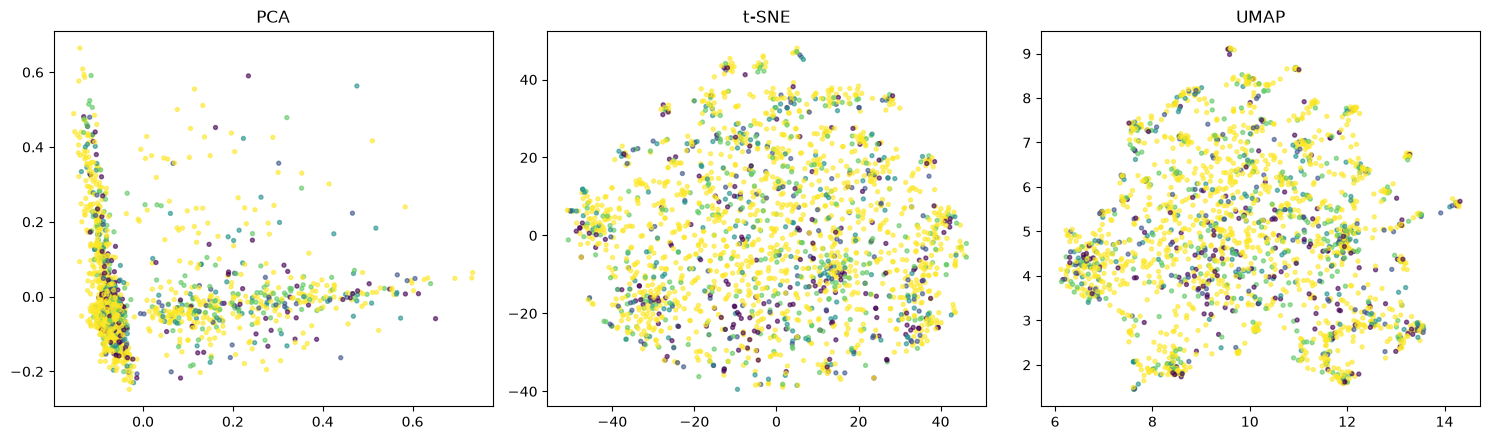

In [9]:
# Objectif : réduire les avis en 2 dimensions avec t-SNE et UMAP,
# puis les comparer à la PCA sur trois graphiques côte à côte.
from sklearn.manifold import TSNE
import umap
import time

# t-SNE.
# perplexity=30 : nombre de voisins que t-SNE regarde autour de chaque point
# init="pca" : point de départ du calcul, pour un résultat plus stable
t0 = time.time()
X_tsne = TSNE(n_components=2, random_state=42, perplexity=30, init="pca").fit_transform(X)
t_tsne = time.time() - t0

# UMAP
t0 = time.time()
X_umap = umap.UMAP(n_components=2, random_state=42).fit_transform(X)
t_umap = time.time() - t0

print(f"Durée de calcul : t-SNE {t_tsne:.0f} s, UMAP {t_umap:.0f} s")

# Les trois graphiques côte à côte. Un point = un avis, la couleur = sa note
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, Z, titre in zip(axes, [X_pca, X_tsne, X_umap], ["PCA", "t-SNE", "UMAP"]):
    ax.scatter(Z[:, 0], Z[:, 1], c=df["Score"], cmap="viridis", s=8, alpha=0.6)
    ax.set_title(titre)
plt.tight_layout()
plt.show()

**Lecture du résultat.** La durée de calcul est affichée au-dessus des graphiques. Le calcul d'UMAP peut paraître plus long que celui de t-SNE : à la première utilisation, UMAP prépare ses fonctions, ce qui prend quelques secondes de plus. Si vous relancez la cellule, la différence disparaît presque (sur notre machine : environ 4 s pour t-SNE et 5 s pour UMAP). Avec seulement 2 000 avis, les deux méthodes sont donc à peu près aussi rapides. UMAP devient souvent plus rapide que t-SNE quand il y a beaucoup plus de points.

Les trois graphiques montrent les mêmes 2 000 avis, rangés par trois méthodes différentes. L'exercice suivant vous demande de les lire.

### À vous : lire les graphiques

On veut savoir si ces graphiques montrent des groupes d'avis de même note. Si c'était le cas, on verrait des amas de la même couleur.

**À faire :** regardez les trois graphiques (la couleur indique la note).

**Questions :**
1. Voit-on des groupes de couleurs, c'est-à-dire des avis de même note regroupés ?
2. À votre avis, pourquoi ?

### Réponse

**Question 1 : voit-on des groupes de même couleur ?**
Non. Pour les trois méthodes, les couleurs sont mélangées. On peut le vérifier avec le **coefficient de silhouette**, un score entre -1 et 1 qui mesure si les points d'une même note sont regroupés : proche de 1, les groupes sont bien séparés ; proche de 0, il n'y a pas de groupes. Ici, il est proche de 0 pour les trois méthodes.

**Question 2 : pourquoi ?**
Le TF-IDF décrit les **mots employés** (de quoi parle l'avis), pas **ce que pense le client**. Un avis à 5 étoiles et un avis à 1 étoile sur le même produit utilisent beaucoup de mots communs. La note n'est donc pas ce qui organise les données.

> **À retenir :** une réduction de dimension ne crée pas de groupes qui n'existent pas. Si on ne voit rien, c'est que les variables utilisées ne contiennent pas cette information.

### À vous : le paramètre `perplexity`

On veut voir si le réglage `perplexity` change le dessin. La `perplexity` est le nombre de voisins que t-SNE regarde autour de chaque point.

**À faire :** relancez t-SNE avec `perplexity=5` puis avec `perplexity=100`, et dessinez les deux graphiques côte à côte.

**Questions :**
1. Que change ce paramètre sur le dessin ?
2. Sur un graphique t-SNE, deux amas très éloignés sont-ils forcément très différents ? Pourquoi ?

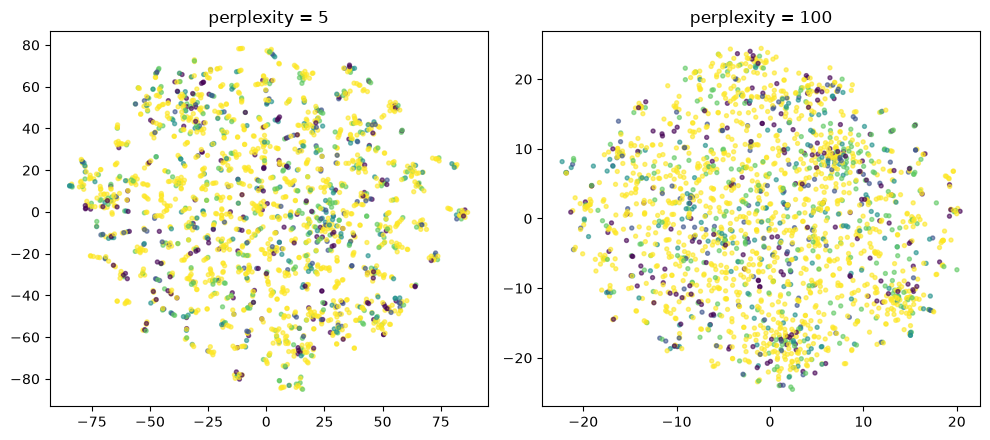

In [10]:
# Objectif : voir si le réglage perplexity (le nombre de voisins regardés autour de chaque point)
# change le dessin de t-SNE.

# Étape 1 : calculer t-SNE deux fois, avec perplexity = 5 puis 100
X_tsne_5 = TSNE(n_components=2, random_state=42, perplexity=5, init="pca").fit_transform(X)
X_tsne_100 = TSNE(n_components=2, random_state=42, perplexity=100, init="pca").fit_transform(X)

# Étape 2 : dessiner les deux résultats côte à côte
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, Z, titre in zip(axes, [X_tsne_5, X_tsne_100], ["perplexity = 5", "perplexity = 100"]):
    ax.scatter(Z[:, 0], Z[:, 1], c=df["Score"], cmap="viridis", s=8, alpha=0.6)
    ax.set_title(titre)
plt.tight_layout()
plt.show()

### Réponse

**Question 1 : que change `perplexity` sur le dessin ?**
C'est le nombre de voisins que t-SNE regarde autour de chaque point.
- Avec une valeur faible (5), il regarde de tout petits voisinages : le dessin est découpé en petits amas.
- Avec une valeur forte (100), il regarde plus large : le dessin est plus regroupé.

Les mêmes données donnent donc des dessins différents.

**Question 2 : deux amas très éloignés sont-ils très différents ?**
Non, pas forcément. t-SNE garde bien les points **proches**, mais la distance entre deux amas éloignés dépend du réglage et du hasard. Elle ne mesure pas la vraie différence entre les groupes.

> **À retenir :** on essaie plusieurs valeurs de `perplexity` avant de tirer une conclusion d'un graphique t-SNE.

# 4. PAA et APCA : réduire une série temporelle

### Concept

Une **série temporelle** est une suite de valeurs mesurées dans le temps : par exemple la température de chaque jour, ou la note moyenne d'un produit chaque mois. Elle peut avoir des milliers de points. Pour la résumer, on la coupe en morceaux appelés **segments**, et on remplace chaque segment par **une seule valeur : sa moyenne**.

**Exemple :** la série 1, 3, 5, 7 coupée en 2 segments donne (1, 3) qui devient 2, et (5, 7) qui devient 6. On est passé de 4 valeurs à 2.

Il y a deux méthodes :
- **PAA** (*Piecewise Aggregate Approximation*) : tous les segments ont la **même longueur**.
- **APCA** (*Adaptive Piecewise Constant Approximation*) : les segments ont une **longueur variable**. Il y a plus de segments (et plus courts) là où la série varie beaucoup, et moins de segments (et plus longs) là où elle est stable.

Référence : E. Keogh, K. Chakrabarti, M. Pazzani, S. Mehrotra, [*Locally Adaptive Dimensionality Reduction for Indexing Large Time Series Databases*](https://www.cs.ucr.edu/~eamonn/sigmod_apca_2001.pdf), ACM SIGMOD, 2001.

### Démo : la note moyenne mensuelle d'un produit

Un produit a reçu 556 avis. On calcule la note moyenne **par mois**. Si un mois n'a aucun avis, on le remplit avec une valeur intermédiaire entre le mois d'avant et le mois d'après : c'est l'**interpolation**.

On travaille par mois et non par semaine, car la plupart des semaines n'ont qu'un ou deux avis, et la courbe serait trop irrégulière.

Nombre de mois : 72


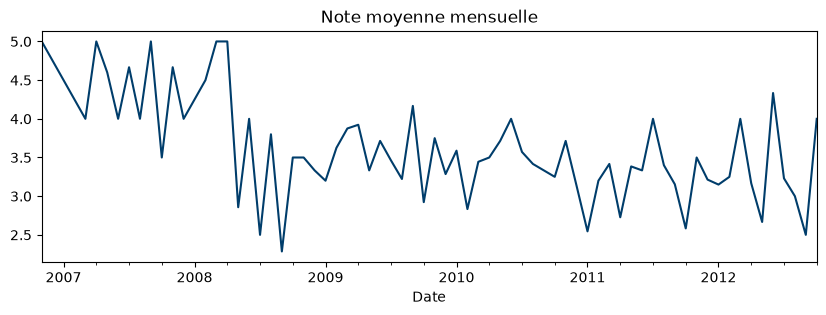

In [11]:
# Objectif : obtenir une série simple : la note moyenne de chaque mois pour un produit.

# Chaque ligne est un avis, avec sa date (Date) et sa note (Score)
ts = pd.read_csv(f"{DATA}/amazon_top_product_timeseries.csv", parse_dates=["Date"])

# set_index("Date") : la date devient l'index (l'étiquette des lignes)
# resample("ME").mean() : on regroupe les avis par mois ("ME" = fin de mois), et on fait la moyenne des notes
# interpolate() : les mois sans avis sont remplis par une valeur intermédiaire
monthly = ts.set_index("Date")["Score"].resample("ME").mean().interpolate()
print("Nombre de mois :", len(monthly))

# Courbe de la note moyenne par mois
fig, ax = plt.subplots(figsize=(10, 3))
monthly.plot(ax=ax, color="#003D6B")
ax.set_title("Note moyenne mensuelle")
plt.show()

**Lecture de la courbe.** La série compte 72 mois, de novembre 2006 à octobre 2012. La note moyenne baisse nettement : environ 4,4 pendant la première année, environ 3,3 pendant la dernière. Le mois le plus bas est septembre 2008 (2,3).


### Démo : résumer la série avec PAA et APCA

On résume la série de 72 mois avec les deux méthodes. Pour comparer, on calcule l'**erreur** de chaque résumé : pour chaque mois, on regarde l'écart entre la vraie valeur et la valeur de son segment, on le met au carré, puis on additionne tout. Plus l'erreur est petite, plus le résumé est fidèle à la vraie série.

Dans la méthode APCA de ce TD, le réglage `max_error` est l'erreur maximale qu'on accepte dans un segment : un segment s'agrandit tant que son erreur reste sous `max_error`.


PAA  : 8 segments, erreur totale = 13.5
APCA : 8 segments, erreur totale = 13.8


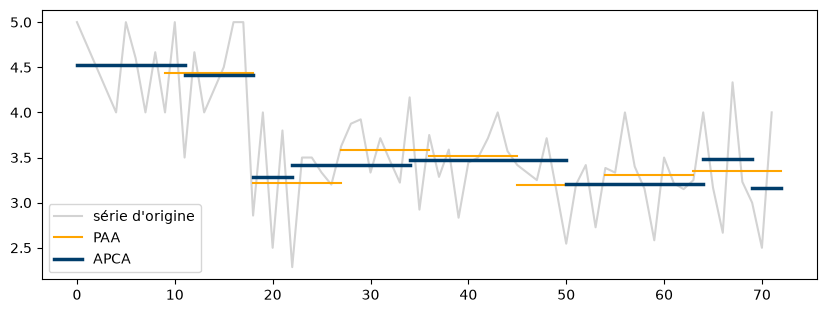

In [12]:
# Objectif : résumer la série avec PAA et APCA, puis comparer l'erreur
# (à quel point le résumé s'éloigne de la vraie série).

# PAA : on coupe la série en n_segments morceaux de même longueur,
# et chaque morceau est remplacé par sa moyenne
def paa(series, n_segments):
    values = series.values                 # les notes sous forme de liste de nombres
    n = len(values)
    seg_len = n // n_segments              # longueur d'un segment
    segments = []
    for i in range(n_segments):
        start = i * seg_len
        end = start + seg_len if i < n_segments - 1 else n   # le dernier segment prend le reste
        segments.append((start, end, values[start:end].mean()))   # (début, fin, moyenne)
    return segments


# APCA (version simple) : on agrandit un segment tant que son erreur reste sous max_error
# L'erreur d'un segment = somme des carrés des écarts entre chaque valeur et la moyenne du segment
def apca(series, max_error):
    values = series.values
    n = len(values)
    segments = []
    start = 0
    while start < n:
        end = start
        while end < n:
            seg = values[start:end + 1]
            err = np.sum((seg - seg.mean()) ** 2)
            if err > max_error and end > start:
                break                       # le segment est devenu trop imprécis : on s'arrête
            end += 1
        segments.append((start, end, values[start:end].mean()))
        start = end
    return segments


# Erreur totale : à quel point la série résumée s'écarte de la vraie série
def erreur_totale(series, segments):
    values = series.values
    return sum(np.sum((values[s:e] - m) ** 2) for s, e, m in segments)


seg_paa = paa(monthly, n_segments=8)
seg_apca = apca(monthly, max_error=2.0)

print("PAA  :", len(seg_paa), "segments, erreur totale =", round(erreur_totale(monthly, seg_paa), 1))
print("APCA :", len(seg_apca), "segments, erreur totale =", round(erreur_totale(monthly, seg_apca), 1))

# Dessin : série d'origine en gris, PAA en orange, APCA en bleu
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(monthly.values, color="lightgray", label="série d'origine")
for i, (s, e, m) in enumerate(seg_paa):
    ax.plot([s, e], [m, m], color="orange", label="PAA" if i == 0 else None)
for i, (s, e, m) in enumerate(seg_apca):
    ax.plot([s, e], [m, m], color="#003D6B", linewidth=2.5, label="APCA" if i == 0 else None)
ax.legend()
plt.show()

**Lecture du résultat**
- Les deux méthodes résument les 72 mois avec 8 segments, avec une erreur du même ordre : 13,5 pour la PAA et 13,8 pour l'APCA.
- **PAA** (en orange) : tous les segments ont la même longueur, 9 mois.
- **APCA** (en bleu) : les segments ont des longueurs différentes, de 3 à 16 mois.
  - Le segment le plus long (16 mois, entre le mois 34 et le mois 50) correspond à une période où la note est stable, autour de 3,5.
  - Les segments courts sont là où la note change : 4 mois au moment de la chute (mois 18 à 22), puis 3 mois à la fin.
- Le premier segment de l'APCA a une note moyenne de 4,5. À partir de la chute, vers 2008, les segments restent entre 3,2 et 3,5.

> **À retenir :** l'APCA ne coupe pas la série n'importe où : elle met des segments courts là où il se passe quelque chose, et des segments longs là où rien ne change.

### À vous : le réglage de `max_error`

On veut voir ce que change `max_error`, l'erreur maximale autorisée dans un segment.

**À faire :** lancez `apca()` avec `max_error=1.0` puis avec `max_error=5.0`. Pour chaque cas, affichez le nombre de segments et l'erreur totale.

**Questions :**
1. Que se passe-t-il quand on augmente `max_error` ?
2. Quel compromis faut-il trouver ?

In [13]:
# Objectif : voir ce que change max_error (l'erreur maximale autorisée dans un segment)
# sur le nombre de segments et sur la fidélité du résumé.

# Pour chaque valeur de max_error :
for me in [1.0, 5.0]:
    # Étape 1 : calculer les segments
    seg = apca(monthly, max_error=me)
    # Étapes 2 et 3 : afficher le nombre de segments et l'erreur totale
    print("max_error =", me, "->", len(seg), "segments, erreur totale =", round(erreur_totale(monthly, seg), 1))

max_error = 1.0 -> 17 segments, erreur totale = 10.4
max_error = 5.0 -> 4 segments, erreur totale = 14.5


### Réponse

| `max_error` | Segments | Erreur totale |
|---|---:|---:|
| 1,0 | 17 | 10,4 |
| 2,0 | 8 | 13,8 |
| 5,0 | 4 | 14,5 |

**Question 1 : que se passe-t-il quand on augmente `max_error` ?**
On accepte plus d'erreur dans chaque segment, donc il y a **moins de segments**. Le résumé est plus court, mais moins fidèle à la vraie série.

**Question 2 : quel compromis faut-il trouver ?**
Entre la **taille** du résumé et sa **fidélité** :
- peu de segments : résumé compact, mais éloigné de la vraie série ;
- beaucoup de segments : résumé fidèle, mais peu réduit.

On choisit selon ce qu'on veut faire : stocker, comparer des séries ou repérer des tendances.

> **À noter :** ici, notre APCA simple à 8 segments (erreur 13,8) n'est pas meilleure que le PAA à 8 segments (erreur 13,5). L'APCA complet est surtout utile pour des séries avec de longues zones stables et quelques brusques variations.

# 5. Bilan

| Méthode | À quoi elle sert | Ses points forts | À faire attention à |
|---|---|---|---|
| PCA | réduire le nombre de colonnes numériques | rapide, on sait combien d'information on garde (variance expliquée) | standardiser avant ; peu efficace sur du texte |
| t-SNE | dessiner les données en 2D | fait bien ressortir les petits groupes de points voisins | la distance entre deux amas ne veut rien dire ; le résultat dépend de `perplexity` |
| UMAP | dessiner les données en 2D | souvent plus rapide que t-SNE quand il y a beaucoup de points (pas visible ici, avec 2 000 avis) | mêmes précautions que t-SNE |
| PAA / APCA | résumer une série temporelle | résumé court de la série | plus il y a de segments, plus le résumé est fidèle mais moins il est court |